In [69]:
import pandas as pd
import numpy as np
import json
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

In [71]:
# Load the preprocessed dataset
df = pd.read_csv('../../Edge-IIoTset_ML-112.csv')

In [72]:
df.head(10)

,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns_4,dns_5,dns_6,dns_7,mqtt1_0,mqtt1_1,mqtt1_2,mqtt2_0,mqtt3_0,mqtt3_2
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,87.0,3.794211e+09,48707.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,59.0,6.828863e+08,19031.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,194.0,2.337571e+09,39685.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,16724.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.196863e+08,26682.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,0.0,0.0,9047.0,41365.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,365851987.0,3.658520e+08,56450.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,261.0,2.367878e+09,44524.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152245 entries, 0 to 152244
Data columns (total 73 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   arp.opcode               152245 non-null  float64
 1   arp.hw.size              152245 non-null  float64
 2   icmp.checksum            152245 non-null  float64
 3   icmp.seq_le              152245 non-null  float64
 4   icmp.transmit_timestamp  152245 non-null  float64
 5   http.content_length      152245 non-null  float64
 6   http.response            152245 non-null  float64
 7   tcp.ack                  152245 non-null  float64
 8   tcp.ack_raw              152245 non-null  float64
 9   tcp.checksum             152245 non-null  float64
 10  tcp.connection.fin       152245 non-null  float64
 11  tcp.connection.rst       152245 non-null  float64
 12  tcp.connection.syn       152245 non-null  float64
 13  tcp.connection.synack    152245 non-null  float64
 14  tcp.

In [74]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [75]:
print(df['Attack_type'].value_counts())

Attack_type
DDoS         48336
Injection    30048
Malware      29526
Normal       24141
Scanning     19836
MITM           358
Name: count, dtype: int64


In [76]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [77]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [78]:
mi_scores = mutual_info_classif(X, y, discrete_features='auto', random_state=42)
mi_scores = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

In [79]:
# Print top features
print(mi_scores.head(10))

                    feature         score
8               tcp.ack_raw  3.741190e+13
7                   tcp.ack  1.533944e+13
18                  tcp.seq  1.472715e+12
4   icmp.transmit_timestamp  4.262691e+10
20               udp.stream  4.109097e+10
..                      ...           ...
43                  http1_3  6.675187e+00
53                  http3_4  6.675187e+00
49                  http3_0  6.675187e+00
64                    dns_7  5.306491e+00
25   dns.retransmit_request  5.306491e+00

[71 rows x 2 columns]


In [80]:
k = 50
selected_features = mi_scores.head(k).index.tolist()  # Select top k features

In [81]:
# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)

# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [82]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (106571, 67)
X_val shape: (15225, 67)
X_test shape: (30449, 67)


In [83]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [84]:
# Define the parameter grid
param_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 500],
    'num_leaves': [31, 50, 100],
    'max_depth': [-1, 10, 20],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [0, 0.1, 0.5]
}

# Define early stopping parameters
fit_params = {
    'eval_set': [(X_val, y_val)],
    'eval_metric': ['multi_logloss', 'multi_error'] ,
    'callbacks': [early_stopping(stopping_rounds=10), log_evaluation(period=10)],
}

In [85]:
# Initialize the LightGBM classifier
def light_gbm_model():
    _model = LGBMClassifier(
        objective='multiclass',
        num_class=6,
        random_state=42
    )
    return _model

model = light_gbm_model()

In [86]:
# Train the model
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1)
grid_search.fit(X_train, y_train, **fit_params)

Fitting 5 folds for each of 729 candidates, totalling 3645 fits
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004351 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2805
[LightGBM] [Info] Number of data points in the train set: 85256, number of used features: 57
[LightGBM] [Info] Start training from score -1.842302
[LightGBM] [Info] Start training from score -1.145793
[LightGBM] [Info] Start training from score -2.038803
[LightGBM] [Info] Start training from score -1.618818
[LightGBM] [Info] Start training from score -6.055096
[LightGBM] [Info] Start training from score -1.645515
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 10 rounds
[10]	valid_0's multi_logloss: 1.23936	valid_0's 

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Training until validation scores don't improve for 10 rounds
[10]	valid_0's multi_logloss: 1.24026	valid_0's multi_error: 0.612151
[20]	valid_0's multi_logloss: 1.01223	valid_0's multi_error: 0.0342857
[30]	valid_0's multi_logloss: 0.84042	valid_0's multi_error: 0.0318555
[40]	valid_0's multi_logloss: 0.706387	valid_0's multi_error: 0.0302791
[50]	valid_0's multi_logloss: 0.59883	valid_0's multi_error: 0.0302135
Early stopping, best iteration is:
[42]	valid_0's multi_logloss: 0.68299	valid_0's multi_error: 0.0302135


/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003257 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2806
[LightGBM] [Info] Number of data points in the train set: 85257, number of used features: 57
[LightGBM] [Info] Start training from score -1.842240
[LightGBM] [Info] Start training from score -1.145768
[LightGBM] [Info] Start training from score -2.038815
[LightGBM] [Info] Start training from score -1.618830
[LightGBM] [Info] Start training from score -6.055108
[LightGBM] [Info] Start training from score -1.645588
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 10 rounds
[10]	valid_0's multi_logloss: 1.24023	valid_0's multi_error: 0.609787
[20]	valid_0's multi_logloss: 1.01298	vali

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (7,282 outputs left out)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004161 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2804
[LightGBM] [Info] Number of data points in the train set: 85257, number of used features: 56
[LightGBM] [Info] Start training from score -1.842314
[LightGBM] [Info] Start training from score -1.145804
[LightGBM] [Info] Start training from score -2.038725
[LightGBM] [Info] Start training from score -1.618830
[LightGBM] [Info] Start training from score -6.055108
[LightGBM] [Info] Start training from score -1.645527
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007499 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2824
[LightGBM] [Info] Number of data points in the train set: 106571, number of used features: 58
[LightGBM] [Info] Start training from score -1.842267
[LightGBM] [Info] Start training from score -1.145780
[LightGBM] [Info] Start training from score -2.038795
[LightGBM] [Info] Start training from score -1.618828
[LightGBM] [Info] Start training from score -6.055106
[LightGBM] [Info] Start training from score -1.645561
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 10 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further spli

GridSearchCV(cv=5,
             estimator=LGBMClassifier(num_class=6, objective='multiclass',
                                      random_state=42),
             param_grid={'learning_rate': [0.01, 0.05, 0.1],
                         'max_depth': [-1, 10, 20],
                         'n_estimators': [100, 200, 500],
                         'num_leaves': [31, 50, 100],
                         'reg_alpha': [0, 0.1, 0.5],
                         'reg_lambda': [0, 0.1, 0.5]},
             scoring='accuracy', verbose=1)

In [87]:
print("Best Hyperparameters:")
print(grid_search.best_params_)

Best Hyperparameters:
{'learning_rate': 0.1, 'max_depth': -1, 'n_estimators': 100, 'num_leaves': 31, 'reg_alpha': 0, 'reg_lambda': 0.5}


In [88]:
print("Best Estimator:")
print(grid_search.best_estimator_)

Best Estimator:
LGBMClassifier(num_class=6, objective='multiclass', random_state=42,
               reg_alpha=0, reg_lambda=0.5)


In [89]:
# Retrieve the best model
best_model = grid_search.best_estimator_

# Predict on the test set
y_pred = best_model.predict(X_test)

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [90]:
y_pred_classes = y_pred

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))]))


Accuracy: 0.9759598016355217
Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      4837
        DDoS       0.98      0.99      0.99      9594
    Scanning       1.00      0.99      0.99      4004
   Injection       0.91      0.97      0.94      5892
        MITM       1.00      1.00      1.00        80
     Malware       1.00      0.92      0.96      6042

    accuracy                           0.98     30449
   macro avg       0.98      0.98      0.98     30449
weighted avg       0.98      0.98      0.98     30449



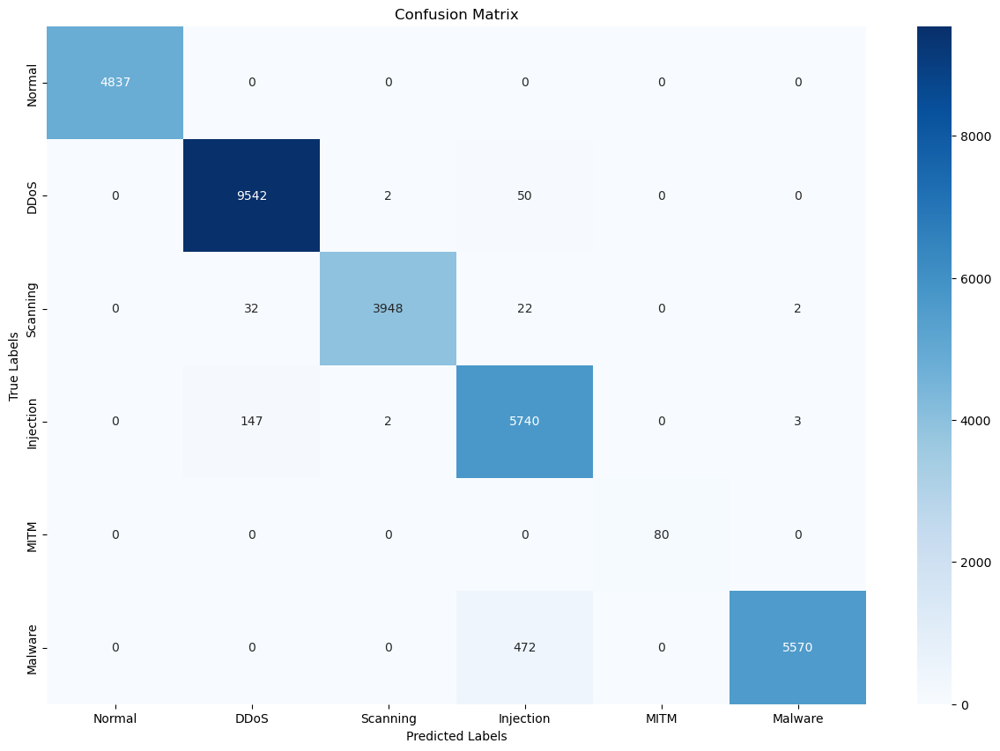

In [91]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

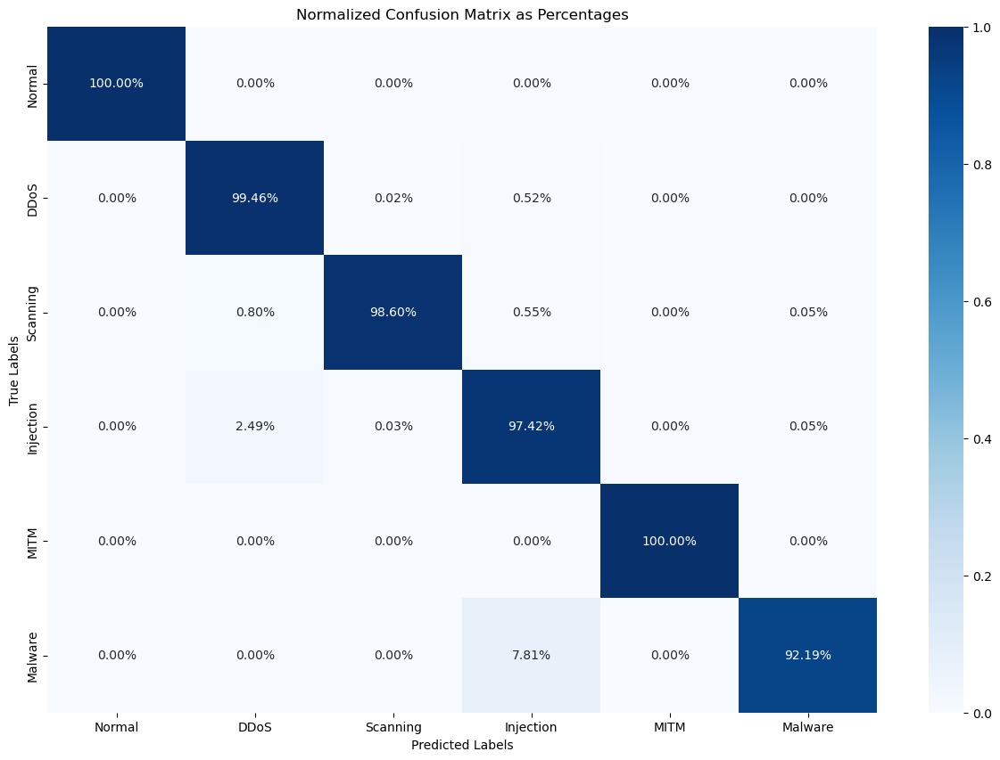

In [92]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()

In [93]:
# Save the model
joblib.dump(best_model, 'lgbm_model_6.pkl')

['lgbm_model_6.pkl']

In [ ]:
with open('HP-LightGBM_6.json', 'w') as f:
    json.dump(grid_search.best_params_, f)